In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import datasets, layers, models

# imported libraries
# tensorFlow Keras provides the CIFAR-10 dataset and the tools
# required to build, train and evaluate a neural network



In [ ]:
(training_images, training_labels), (testing_images, testing_labels) = datasets.cifar10.load_data()

# CIFAR-10 contains 60,000 labelled colour images across
# 10 classes. Each image is 32 x 32 pixels with 3 colour channels

In [ ]:
training_images, testing_images = training_images/255, testing_images/255
class_names=['aeroplane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# define the class names in the same order as the CIFAR-10
# numerical labels, so predictions can be interpreted as text

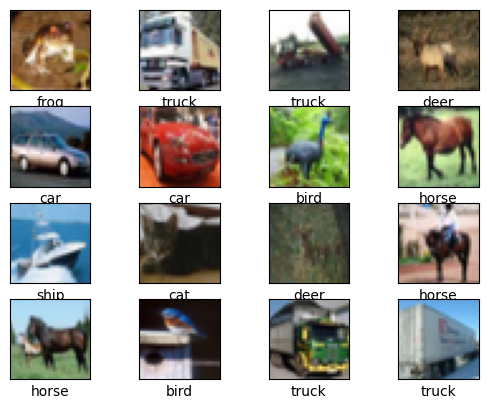

In [ ]:
for i in range(16):
    # create the next position in the 4 x 4 subplot grid
    plt.subplot(4,4,i+1)
    # hide the axis tick marks to keep the visualisation clear
    plt.xticks([])
    plt.yticks([])
    # display image
    plt.imshow(training_images[i], cmap=plt.cm.binary)
    # retrieve the correct class name using the image's label
    plt.xlabel(class_names[training_labels[i][0]])

plt.show()

# Display the first 16 training images in a 4 x 4 grid.
# This helps us inspect the dataset and understand the
# different types of images the model will learn to recognise

In [ ]:
# use a smaller subset of the dataset to reduce training time
# while developing and experimenting with the model
#
# this uses the first 20,000 training images and the first
# 4,000 testing images. The smaller sample may affect accuracy
# and may not represent every class equally well
#
# these slices select the first records; they do not randomly
# sample the dataset

training_images = training_images[:20000] 
training_labels = training_labels[:20000]
testing_images = testing_images[:4000]
testing_labels = testing_labels[:4000]

In [53]:
model = models.load_model('image_classification_model.h5')

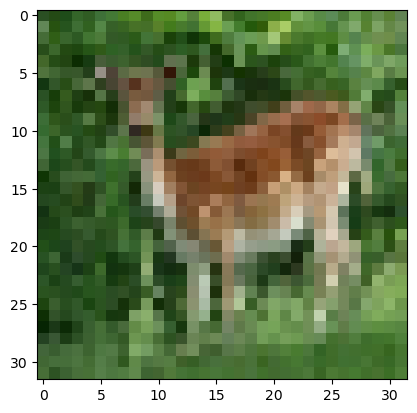

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
Predicted class: deer


In [ ]:
img = cv.imread('deertestimage.jpg')

# convert the image from OpenCV's BGR colour format to RGB
# so the colour channels are consistent with the training images
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# Resize the image to 32 x 32 pixels
img = cv.resize(img, (32, 32))

# Display the image
plt.imshow(img)
plt.show()

# Add a batch dimension to the image and normalise pixel values
# from 0–255 to 0–1, matching the preprocessing used during training.
# The model returns a probability score for each possible class
prediction = model.predict(np.array([img]) / 255.0)

# Get the index of the highest prediction
index = np.argmax(prediction)

# display the predicted class using its corresponding label
print("Predicted class:", class_names[index])

